# Final Project Checkpoint
## Predicting Retrieval Failure in Consumer Health Question Answering

**Jeremy Childress** · Programming for Health Data Science

**Question.** Many AI tools answer health questions by first searching a set of documents for relevant passages. If the search returns the wrong passage, the tool can still give a confident but wrong answer. This project asks whether we can predict, before an answer is written, that a search is likely to fail.

**Data.** MedQuAD, consumer health questions paired with answers from NIH websites (Ben Abacha & Demner-Fushman, 2019). https://github.com/abachaa/MedQuAD

**Target.** `failure` (1 = the correct answer is not in the top 10 search results, 0 = it is). MedQuAD does not include this variable. I create it by running four search methods on each question and checking the result against MedQuAD's known question and answer pairs.

### Notebook outline
1. Configuration
2. Imports
3. Helper functions
4. Data import and validation
5. Data cleaning and preprocessing
6. Descriptive statistics
7. Running the search methods (creating the target)
8. Feature engineering and validation of the modeling table
9. Exploratory visualizations
10. Inferential statistics
11. Supervised machine learning models
12. Model evaluation and comparison
13. Feature importance
14. Interpretation of findings
15. Pipeline enhancements

## 1. Configuration
*(Enhancement 1)* All settings live in one cell, so the whole pipeline can be changed or rerun without editing code further down.

In [1]:
# =============================================================================
# CONFIGURATION
# =============================================================================
RANDOM_STATE = 42            # used everywhere for reproducibility
SAMPLE_SIZE  = 2000          # number of questions to search
TOP_K        = 10            # a search succeeds if the correct answer is in the top K results
MIN_QTYPE_N  = 100           # question types with fewer questions are grouped into "other"
N_FOLDS      = 5             # cross-validation folds
LSA_DIMS     = 200           # number of dimensions for the LSA (semantic) search method

# Data locations, tried in order (see Section 4)
REPO_RAW       = 'https://raw.githubusercontent.com/f007yss/dataset-selection-lab/main/data/'
RAW_FILE       = 'medquad_raw.csv.gz'
RESULTS_FILE   = 'retrieval_results.csv'

# If True, reuse saved search results instead of rerunning all four search methods.
# The saved file was produced by this notebook with the settings above.
USE_CACHED_RETRIEVAL = False

## 2. Imports

In [2]:
import os, re, glob, warnings
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse, stats
from IPython.display import display

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             balanced_accuracy_score, recall_score, precision_score, f1_score,
                             accuracy_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report)
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print('xgboost not installed, skipping the XGBoost model')

warnings.filterwarnings('ignore')
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 80)
print('Libraries loaded. Random seed =', RANDOM_STATE)

Libraries loaded. Random seed = 42


## 3. Helper Functions
*(Enhancement 2)* Repeated steps are written once as functions: loading, validation, the four search methods, evaluation, and plotting. Each function has a short docstring.

In [3]:
# -----------------------------------------------------------------------------
# Data loading
# -----------------------------------------------------------------------------
def parse_medquad_xml(folder):
    """Read the original MedQuAD XML files into a DataFrame."""
    rows = []
    for f in sorted(glob.glob(os.path.join(folder, '*_QA', '*.xml'))):
        doc = ET.parse(f).getroot()
        for qa in doc.iter('QAPair'):
            q, a = qa.find('Question'), qa.find('Answer')
            rows.append({'qid': q.get('qid'), 'source': doc.get('source'), 'doc_id': doc.get('id'),
                         'focus': (doc.findtext('Focus') or '').strip(), 'qtype': q.get('qtype'),
                         'question': (q.text or '').strip(),
                         'answer': (a.text or '').strip() if a is not None else ''})
    return pd.DataFrame(rows)


def load_medquad():
    """Load MedQuAD from the first location that works:
    1) local data/ folder, 2) this project's GitHub repo, 3) rebuild from the original MedQuAD XML."""
    local = os.path.join('data', RAW_FILE)
    if os.path.exists(local):
        print('Loaded from local file:', local)
        return pd.read_csv(local, dtype=str, keep_default_na=False)
    try:
        df = pd.read_csv(REPO_RAW + RAW_FILE, dtype=str, keep_default_na=False, compression='gzip')
        print('Loaded from GitHub repo')
        return df
    except Exception as e:
        print('Repo copy not available (', type(e).__name__, '), rebuilding from original MedQuAD XML')
    if not os.path.exists('MedQuAD'):
        os.system('git clone -q --depth 1 https://github.com/abachaa/MedQuAD.git')
    return parse_medquad_xml('MedQuAD')


# -----------------------------------------------------------------------------
# Validation  (Enhancement 3)
# -----------------------------------------------------------------------------
def validate_raw(df):
    """Stop with a clear message if the raw data is not what the pipeline expects."""
    required = ['qid', 'source', 'doc_id', 'focus', 'qtype', 'question', 'answer']
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f'Missing required columns: {missing}')
    if len(df) == 0:
        raise ValueError('Dataset is empty')
    dup_ids = df['qid'].duplicated().sum()
    if dup_ids:
        print(f'Warning: {dup_ids:,} question IDs are reused across NIH sources, so a new unique ID (uid) is created')
    print(f'Raw data passed validation: {len(df):,} rows, {df.shape[1]} columns')


def validate_model_table(df, features, target):
    """Check the modeling table against the course requirements before any model is trained."""
    problems = []
    if df[target].nunique() != 2 or not set(df[target].unique()) <= {0, 1}:
        problems.append('target is not binary 0/1')
    if len(df) < 300:
        problems.append('fewer than 300 observations')
    if len(features) < 10:
        problems.append('fewer than 10 predictors')
    if df[features].isna().any().any():
        problems.append('missing values in predictors: ' + str(df[features].columns[df[features].isna().any()].tolist()))
    if problems:
        raise ValueError('Modeling table failed validation: ' + '; '.join(problems))
    print(f'Modeling table passed validation: {len(df):,} rows, {len(features)} predictors, binary target')


# -----------------------------------------------------------------------------
# Search methods
# -----------------------------------------------------------------------------
TOKEN = r'(?u)\b[a-z0-9]+\b'

def build_bm25(passages, k1=1.5, b=0.75):
    """Vectorized BM25 keyword search. Returns (vectorizer, weighted document matrix, idf)."""
    cv = CountVectorizer(token_pattern=TOKEN, lowercase=True)
    tf = cv.fit_transform(passages).tocsr().astype(float)
    n, dl = tf.shape[0], np.asarray(tf.sum(axis=1)).ravel()
    df_ = np.bincount(tf.indices, minlength=tf.shape[1])
    idf = np.log((n - df_ + 0.5) / (df_ + 0.5) + 1)
    tf = tf.tocoo()
    denom = tf.data + k1 * (1 - b + b * dl[tf.row] / dl.mean())
    w = sparse.csr_matrix((idf[tf.col] * tf.data * (k1 + 1) / denom, (tf.row, tf.col)), shape=tf.shape)
    return cv, w, idf


def rrf(rank_lists, k=60):
    """Reciprocal rank fusion: combine several ranked lists into one score per passage."""
    scores = {}
    for ranks in rank_lists:
        for r, pid in enumerate(ranks):
            scores[pid] = scores.get(pid, 0) + 1 / (k + r + 1)
    return scores


# -----------------------------------------------------------------------------
# Evaluation  (based on the course get_metrics_score function, with extra metrics)
# -----------------------------------------------------------------------------
def fmt_p(p):
    """Format a p-value for reporting."""
    return '< 0.001' if p < 0.001 else f'{p:.3f}'


def get_scores(model, X):
    """Probability of failure, or a decision score if the model has no probabilities."""
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def evaluate(model, X_train, X_test, y_train, y_test, name):
    """Train/test metrics for one fitted model. Failure (1) is the positive class."""
    row = {'Model': name}
    for split, X, y in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
        p, s = model.predict(X), get_scores(model, X)
        row[f'{split} ROC-AUC'] = roc_auc_score(y, s)
        row[f'{split} PR-AUC']  = average_precision_score(y, s)
    row['Test Recall']        = recall_score(y_test, model.predict(X_test))
    row['Test Precision']     = precision_score(y_test, model.predict(X_test), zero_division=0)
    row['Test F1']            = f1_score(y_test, model.predict(X_test))
    row['Test Bal. Accuracy'] = balanced_accuracy_score(y_test, model.predict(X_test))
    row['Test Accuracy']      = accuracy_score(y_test, model.predict(X_test))
    if hasattr(model, 'predict_proba'):
        row['Test Brier'] = brier_score_loss(y_test, model.predict_proba(X_test)[:, 1])
    return row


def plot_confusion(model, X, y, title):
    """Confusion matrix with counts and percentages."""
    cm = confusion_matrix(y, model.predict(X))
    labels = np.array([f'{c}\n{c / cm.sum():.1%}' for c in cm.flatten()]).reshape(2, 2)
    plt.figure(figsize=(6, 4.5))
    sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False,
                xticklabels=['Pred: success', 'Pred: failure'], yticklabels=['True: success', 'True: failure'])
    plt.title(title)
    plt.tight_layout()
    plt.show()
    print(classification_report(y, model.predict(X), target_names=['success', 'failure']))

print('Helper functions defined.')

Helper functions defined.


## 4. Data Import and Validation
The loader tries a local copy, then the copy saved in this project's GitHub repo, and finally rebuilds the data from the original MedQuAD XML files. This means the notebook runs in Colab without any manual upload.

In [4]:
raw = load_medquad()
validate_raw(raw)
raw['uid'] = np.arange(len(raw))   # MedQuAD question IDs restart in each source, so they are not unique
raw.head(3)

Loaded from local file: data/medquad_raw.csv.gz


Raw data passed validation: 46,882 rows, 7 columns


,qid,source,doc_id,focus,qtype,question,answer,uid
0,0000001-1,ADAM,0000001,A guide to clinical trials for cancer,information,What is (are) A guide to clinical trials for cancer ?,,0
1,0000001-2,ADAM,0000001,A guide to clinical trials for cancer,research,what research (or clinical trials) is being done for A guide to clinical tri...,,1
2,0000001-3,ADAM,0000001,A guide to clinical trials for cancer,research,what research (or clinical trials) is being done for A guide to clinical tri...,,2


In [5]:
print('Shape:', raw.shape)
print(raw.dtypes)
print('\nQuestions per source:')
print(raw['source'].value_counts())

Shape: (46882, 8)
qid           str
source        str
doc_id        str
focus         str
qtype         str
question      str
answer        str
uid         int64
dtype: object

Questions per source:
source
ADAM                     17348
MPlusDrugs               12889
GHR                       5430
GARD                      5394
NIDDK                     1192
NINDS                     1088
MPlusHealthTopics          981
MPlusHerbsSupplements      792
NIHSeniorHealth            769
CancerGov                  729
CDC                        270
Name: count, dtype: int64


## 5. Data Cleaning and Preprocessing
- **Missing answers.** Three MedlinePlus subsets (ADAM, MPlusDrugs, MPlusHerbsSupplements) had their answers removed for copyright reasons. Those rows cannot be used.
- **Duplicate questions.** Some question text appears more than once with different answers, so the correct answer is ambiguous. Those questions are dropped.
- **Duplicate answers.** Identical answers are searched as one passage, so finding the duplicate is not counted as a miss.
- **Rare question types** are grouped into "other" so no category is too small to learn from *(Enhancement 4)*.

In [6]:
data = raw.copy()
data['has_answer'] = data['answer'].str.len() > 0

cleaning_log = {'Raw rows': len(data)}
data = data[data['has_answer']]
cleaning_log['After dropping missing answers'] = len(data)
data = data[~data['question'].duplicated(keep=False)]
cleaning_log['After dropping duplicate questions'] = len(data)
display(pd.Series(cleaning_log, name='rows').to_frame())

# Group rare question types
counts = data['qtype'].value_counts()
data['qtype_group'] = np.where(data['qtype'].map(counts) >= MIN_QTYPE_N, data['qtype'], 'other')

# One passage per unique answer text
passages = data['answer'].drop_duplicates().reset_index(drop=True)
data['pid'] = data['answer'].map({t: i for i, t in enumerate(passages)})
passage_doc = data.drop_duplicates('pid').set_index('pid')['doc_id'].sort_index().values
print(f'Unique answer passages to search: {len(passages):,}')

,rows
Raw rows,46882
After dropping missing answers,15848
After dropping duplicate questions,13675


Unique answer passages to search: 13,169


## 6. Descriptive Statistics

In [7]:
data['q_words']     = data['question'].str.split().str.len()
data['a_words']     = data['answer'].str.split().str.len()
data['focus_words'] = data['focus'].str.split().str.len()

display(data[['q_words', 'a_words', 'focus_words']].describe().round(1))
for col in ['q_words', 'a_words']:
    print(f'{col}: skewness = {stats.skew(data[col]):.2f}')

,q_words,a_words,focus_words
count,13675.0,13675.0,13675.0
mean,8.4,186.5,3.0
std,2.3,228.5,1.6
min,3.0,1.0,0.0
25%,7.0,67.0,2.0
50%,8.0,131.0,3.0
75%,10.0,246.0,4.0
max,27.0,3708.0,17.0


q_words: skewness = 0.72
a_words: skewness = 6.24


In [8]:
display(data['qtype_group'].value_counts().to_frame('questions'))

,questions
qtype_group,
information,3414
symptoms,2566
treatment,2015
inheritance,1318
frequency,1120
genetic changes,1087
causes,545
exams and tests,507
research,355


## 7. Running the Search Methods (Creating the Target)
Four search methods are run on the same sample of questions.

| Method | How it works |
|---|---|
| **BM25** | Keyword matching, weighting rare words more heavily |
| **TF-IDF** | Keyword matching using cosine similarity of TF-IDF vectors |
| **LSA** | Semantic search. TF-IDF vectors are compressed to 200 dimensions so related words land near each other |
| **Hybrid** | Combines the BM25 and LSA rankings with reciprocal rank fusion |

For each question and method, the search is a **success** if the question's own answer is in the top 10 results, and a **failure** otherwise.

*(Enhancement 5)* If `USE_CACHED_RETRIEVAL = True` in the configuration cell, saved results are loaded instead, which skips the slowest step.

In [9]:
def run_all_searches(data, passages, sample_size, top_k):
    """Run all four search methods on a sample of questions. Returns one row per question and method."""
    sample = data.sample(sample_size, random_state=RANDOM_STATE).reset_index(drop=True)
    questions = sample['question'].tolist()

    # BM25
    cv, bm25_w, idf = build_bm25(passages)
    q_bin = (cv.transform(questions) > 0).astype(float)
    bm25_scores = (q_bin @ bm25_w.T).toarray()

    # TF-IDF cosine
    tfidf = TfidfVectorizer(token_pattern=TOKEN, sublinear_tf=True, stop_words='english')
    P = tfidf.fit_transform(passages)
    tfidf_scores = (tfidf.transform(questions) @ P.T).toarray()

    # LSA (semantic)
    svd = TruncatedSVD(LSA_DIMS, random_state=RANDOM_STATE)
    P_lsa = normalize(svd.fit_transform(P))
    lsa_scores = normalize(svd.transform(tfidf.transform(questions))) @ P_lsa.T

    # Question-level features that do not depend on the method
    vocab = cv.vocabulary_
    q_idf = [[idf[vocab[w]] for w in re.findall(TOKEN, q.lower()) if w in vocab] for q in questions]
    sample['mean_idf'] = [np.mean(v) if v else 0 for v in q_idf]
    sample['max_idf']  = [np.max(v) if v else 0 for v in q_idf]

    rows = []
    for i, row in sample.iterrows():
        ranked = {
            'BM25':   np.argsort(-bm25_scores[i])[:100],
            'TF-IDF': np.argsort(-tfidf_scores[i])[:100],
            'LSA':    np.argsort(-lsa_scores[i])[:100],
        }
        fused = rrf([ranked['BM25'], ranked['LSA']])
        ranked['Hybrid'] = np.array(sorted(fused, key=fused.get, reverse=True)[:100])
        raw_scores = {'BM25': bm25_scores[i], 'TF-IDF': tfidf_scores[i], 'LSA': lsa_scores[i]}

        for method, order in ranked.items():
            top = order[:top_k]
            s = np.array([fused[p] for p in top]) if method == 'Hybrid' else raw_scores[method][top]
            rows.append({
                'uid': row['uid'], 'method': method,
                'success': int(row['pid'] in top),
                'top_score': s[0], 'score_gap': s[0] - s[4],
                'same_page_top10': int((passage_doc[top] == passage_doc[top[0]]).sum()),
            })
    results = pd.DataFrame(rows)
    keep = ['uid', 'source', 'qtype', 'qtype_group', 'question', 'focus', 'q_words', 'focus_words', 'mean_idf', 'max_idf']
    return results.merge(sample[keep], on='uid')


cache = os.path.join('data', RESULTS_FILE)
if USE_CACHED_RETRIEVAL and os.path.exists(cache):
    results = pd.read_csv(cache)
    print('Loaded cached search results from', cache)
elif USE_CACHED_RETRIEVAL:
    try:
        results = pd.read_csv(REPO_RAW + RESULTS_FILE)
        print('Loaded cached search results from GitHub repo')
    except Exception:
        print('No cached results found, running the searches')
        results = run_all_searches(data, passages, SAMPLE_SIZE, TOP_K)
else:
    results = run_all_searches(data, passages, SAMPLE_SIZE, TOP_K)
    os.makedirs('data', exist_ok=True)
    results.to_csv(cache, index=False)
    print('Searches complete. Results saved to', cache)

print(results.shape)
results.groupby('method')['success'].mean().round(3).sort_values().to_frame('success rate')

Searches complete. Results saved to data/retrieval_results.csv
(8000, 15)


,success rate
method,
LSA,0.283
Hybrid,0.505
TF-IDF,0.801
BM25,0.838


## 8. Feature Engineering and Validation of the Modeling Table
*(Enhancement 4, continued)* Raw search scores are on different scales for each method (BM25 scores run into the 30s, cosine scores are between 0 and 1). To make them comparable, I standardize the top score and the score gap **within each method**. I also add a flag for template questions that start with "What is (are)".

The modeling target is `failure = 1 - success`, so the class we care about (failed searches) is the positive class.

In [10]:
df = results.copy()
df['failure'] = 1 - df['success']
for col in ['top_score', 'score_gap']:
    df[col + '_z'] = df.groupby('method')[col].transform(lambda s: (s - s.mean()) / s.std())
df['template_question'] = df['question'].str.startswith('What is (are)').astype(int)

NUMERIC     = ['q_words', 'focus_words', 'mean_idf', 'max_idf', 'top_score_z', 'score_gap_z',
               'same_page_top10', 'template_question']
CATEGORICAL = ['method', 'qtype_group', 'source']
FEATURES    = NUMERIC + CATEGORICAL
TARGET      = 'failure'

validate_model_table(df, FEATURES, TARGET)
print('\nClass balance (failure = 1):')
print(df[TARGET].value_counts(normalize=True).round(3))
df[FEATURES + [TARGET]].head()

Modeling table passed validation: 8,000 rows, 11 predictors, binary target

Class balance (failure = 1):
failure
0    0.607
1    0.393
Name: proportion, dtype: float64


,q_words,focus_words,mean_idf,max_idf,top_score_z,score_gap_z,same_page_top10,template_question,method,qtype_group,source,failure
0,9,3,2.769588,7.613895,1.179892,0.708283,4,0,BM25,symptoms,GARD,0
1,9,3,2.769588,7.613895,-0.041411,-0.610567,2,0,TF-IDF,symptoms,GARD,0
2,9,3,2.769588,7.613895,0.264630,-0.602763,1,0,LSA,symptoms,GARD,1
3,9,3,2.769588,7.613895,0.536406,-0.003913,3,0,Hybrid,symptoms,GARD,1
4,8,2,2.728946,7.981619,0.019836,1.034594,3,0,BM25,treatment,GARD,0


In [11]:
display(df.groupby(TARGET)[NUMERIC].mean().round(2).T.rename(columns={0: 'success', 1: 'failure'}))

failure,success,failure
q_words,8.28,8.75
focus_words,3.00,3.08
mean_idf,2.53,2.54
max_idf,6.77,6.87
top_score_z,0.08,-0.12
score_gap_z,0.05,-0.08
same_page_top10,3.05,1.75
template_question,0.29,0.12


## 9. Exploratory Visualizations

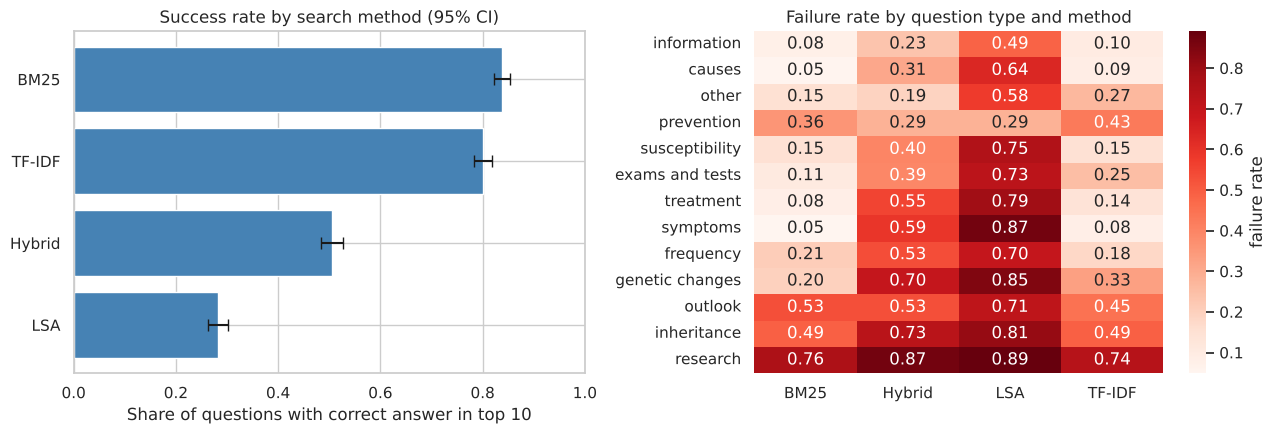

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

rate = df.groupby('method')['success'].mean().sort_values()
n = df.groupby('method').size()[rate.index]
err = 1.96 * np.sqrt(rate * (1 - rate) / n)
axes[0].barh(rate.index, rate.values, xerr=err.values, color='steelblue', capsize=4)
axes[0].set_xlim(0, 1)
axes[0].set_title('Success rate by search method (95% CI)')
axes[0].set_xlabel('Share of questions with correct answer in top 10')

heat = df.pivot_table(index='qtype_group', columns='method', values='failure', aggfunc='mean')
heat = heat.loc[heat.mean(axis=1).sort_values().index]
sns.heatmap(heat, annot=True, fmt='.2f', cmap='Reds', ax=axes[1], cbar_kws={'label': 'failure rate'})
axes[1].set_title('Failure rate by question type and method')
axes[1].set_xlabel(''); axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

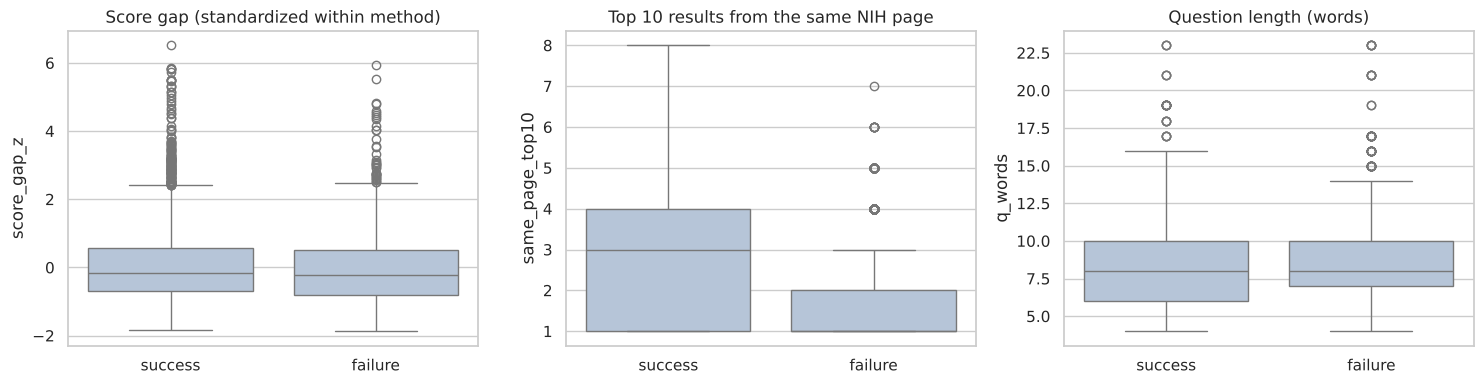

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, label in zip(axes, ['score_gap_z', 'same_page_top10', 'q_words'],
                          ['Score gap (standardized within method)', 'Top 10 results from the same NIH page', 'Question length (words)']):
    sns.boxplot(data=df, x='failure', y=col, ax=ax, color='lightsteelblue')
    ax.set_xticklabels(['success', 'failure'])
    ax.set_xlabel('')
    ax.set_title(label)
plt.tight_layout()
plt.show()

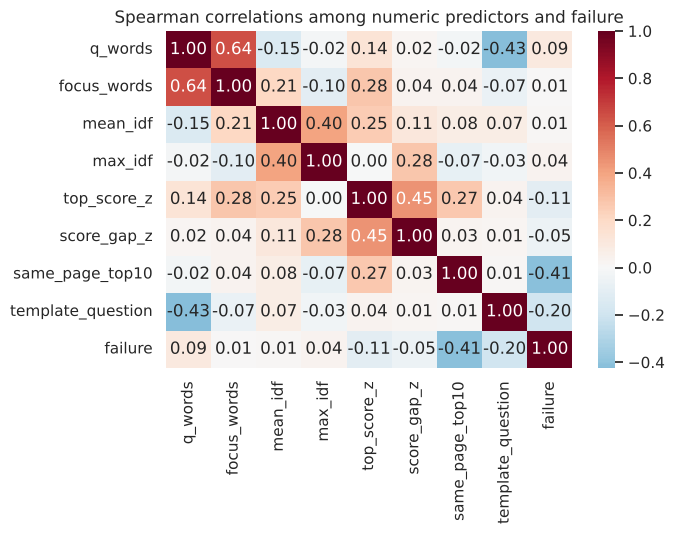

In [14]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[NUMERIC + [TARGET]].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Spearman correlations among numeric predictors and failure')
plt.tight_layout()
plt.show()

## 10. Inferential Statistics
Three questions, each matched to a test from the course materials. Significance level is 0.05.

1. **Do the four search methods fail at different rates on the same questions?** Each question is searched by all four methods, so the outcomes are paired. Cochran's Q test is the right test for paired binary outcomes across more than two groups. Pairwise follow-ups use McNemar's test with a Bonferroni correction.
2. **Is failure related to question type?** Chi-square test of independence.
3. **Do failed searches have smaller score gaps?** The score gap is not normally distributed, so I use the Mann-Whitney U test instead of a t-test.

In [15]:
# 1. Cochran's Q across the four methods (paired by question)
wide = df.pivot(index='uid', columns='method', values='failure')
q = cochrans_q(wide.values)
print(f"Cochran's Q = {q.statistic:.1f}, df = {wide.shape[1] - 1}, p {fmt_p(q.pvalue)}")

# Pairwise McNemar with Bonferroni correction
methods = list(wide.columns)
pairs = [(a, b) for i, a in enumerate(methods) for b in methods[i + 1:]]
rows = []
for a, b in pairs:
    table = pd.crosstab(wide[a], wide[b]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    p = mcnemar(table.values, exact=False, correction=True).pvalue
    rows.append({'Comparison': f'{a} vs {b}', f'{a} failure rate': wide[a].mean(),
                 f'{b} failure rate': wide[b].mean(), 'p (Bonferroni)': min(p * len(pairs), 1)})
mc = pd.DataFrame(rows)
mc['Significant'] = mc['p (Bonferroni)'] < 0.05
mc['p (Bonferroni)'] = mc['p (Bonferroni)'].map(fmt_p)
mc['Failure rates'] = [f'{wide[a].mean():.3f} vs {wide[b].mean():.3f}' for a, b in pairs]
display(mc[['Comparison', 'Failure rates', 'p (Bonferroni)', 'Significant']])

Cochran's Q = 2301.7, df = 3, p < 0.001


,Comparison,Failure rates,p (Bonferroni),Significant
0,BM25 vs Hybrid,0.163 vs 0.495,< 0.001,True
1,BM25 vs LSA,0.163 vs 0.717,< 0.001,True
2,BM25 vs TF-IDF,0.163 vs 0.199,< 0.001,True
3,Hybrid vs LSA,0.495 vs 0.717,< 0.001,True
4,Hybrid vs TF-IDF,0.495 vs 0.199,< 0.001,True
5,LSA vs TF-IDF,0.717 vs 0.199,< 0.001,True


In [16]:
# 2. Chi-square: question type vs failure
ct = pd.crosstab(df['qtype_group'], df['failure'])
chi2, p, dof, expected = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f'Chi-square = {chi2:.1f}, df = {dof}, p {fmt_p(p)}, Cramer\'s V = {cramers_v:.2f}')
print('Smallest expected cell count:', round(expected.min(), 1), '(should be at least 5)')

# 3. Mann-Whitney U: score gap for failures vs successes
gap_fail = df.loc[df['failure'] == 1, 'score_gap_z']
gap_succ = df.loc[df['failure'] == 0, 'score_gap_z']
print('\nShapiro-Wilk normality p (sample of 500):', fmt_p(stats.shapiro(gap_succ.sample(500, random_state=RANDOM_STATE)).pvalue))
u, p = stats.mannwhitneyu(gap_fail, gap_succ, alternative='less')
r = 1 - 2 * u / (len(gap_fail) * len(gap_succ))
print(f'Mann-Whitney U = {u:,.0f}, p {fmt_p(p)}, rank-biserial r = {r:.2f}')
print(f'Median score gap: failure = {gap_fail.median():.2f}, success = {gap_succ.median():.2f}')

Chi-square = 632.9, df = 12, p < 0.001, Cramer's V = 0.28
Smallest expected cell count: 22.0 (should be at least 5)

Shapiro-Wilk normality p (sample of 500): < 0.001
Mann-Whitney U = 7,147,335, p < 0.001, rank-biserial r = 0.06
Median score gap: failure = -0.22, success = -0.16


## 11. Supervised Machine Learning Models

**Splitting.** Each question appears four times (once per method). If the same question landed in both training and test data, the model could memorize it and look better than it is. *(Enhancement 6)* I use `StratifiedGroupKFold`, which keeps all four rows for a question together and keeps the failure rate similar in every fold. One fold (about 20%) is held out as the test set, and the other four folds are used for training and cross-validation.

**Preprocessing.** Numeric predictors are standardized. Categorical predictors are one-hot encoded. All models use balanced class weights (or the equivalent) because failure is the minority class. Preprocessing happens inside each pipeline, so nothing from the test set leaks into training.

In [17]:
X, y, groups = df[FEATURES], df[TARGET], df['uid']
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

assert set(g_train).isdisjoint(set(groups.iloc[test_idx])), 'A question appears in both train and test'
print(f'Train: {len(X_train):,} rows ({g_train.nunique():,} questions), failure rate {y_train.mean():.3f}')
print(f'Test:  {len(X_test):,} rows ({groups.iloc[test_idx].nunique():,} questions), failure rate {y_test.mean():.3f}')

preprocess = ColumnTransformer([
    ('num', StandardScaler(), NUMERIC),
    ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
])
cv_inner = StratifiedGroupKFold(n_splits=N_FOLDS - 1, shuffle=True, random_state=RANDOM_STATE)
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

def make_pipe(clf):
    return Pipeline([('prep', preprocess), ('clf', clf)])

Train: 6,400 rows (1,600 questions), failure rate 0.393
Test:  1,600 rows (400 questions), failure rate 0.394


In [18]:
models = {
    'Logistic Regression': make_pipe(LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE)),
    'Decision Tree':       make_pipe(DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight='balanced', random_state=RANDOM_STATE)),
    'SVM (RBF)':           make_pipe(SVC(kernel='rbf', C=1.0, probability=True, class_weight='balanced', random_state=RANDOM_STATE)),
    'Random Forest':       make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE)),
    'Gradient Boosting':   make_pipe(GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE)),
    'Neural Network (MLP)': make_pipe(MLPClassifier(hidden_layer_sizes=(32, 16), early_stopping=True, max_iter=500, random_state=RANDOM_STATE)),
}
if HAS_XGB:
    models['XGBoost'] = make_pipe(XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                                                colsample_bytree=0.8, scale_pos_weight=pos_weight,
                                                eval_metric='logloss', random_state=RANDOM_STATE))

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print('Trained:', name)

Trained: Logistic Regression
Trained: Decision Tree


Trained: SVM (RBF)


Trained: Random Forest


Trained: Gradient Boosting


Trained: Neural Network (MLP)
Trained: XGBoost


### Hyperparameter tuning
The two most interpretable models are tuned with a small grid search, using grouped cross-validation on the training set and ROC-AUC as the score.

In [19]:
grids = {
    'Logistic Regression (Tuned)': (models['Logistic Regression'], {'clf__C': [0.01, 0.1, 1, 10]}),
    'Random Forest (Tuned)':       (models['Random Forest'], {'clf__max_depth': [6, 12, None], 'clf__min_samples_leaf': [5, 20]}),
}
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, scoring='roc_auc', cv=cv_inner, n_jobs=-1)
    gs.fit(X_train, y_train, groups=g_train)
    models[name] = gs.best_estimator_
    print(f'{name}: best params {gs.best_params_}, CV ROC-AUC {gs.best_score_:.3f}')

Logistic Regression (Tuned): best params {'clf__C': 1}, CV ROC-AUC 0.859


Random Forest (Tuned): best params {'clf__max_depth': None, 'clf__min_samples_leaf': 5}, CV ROC-AUC 0.906


## 12. Model Evaluation and Comparison
*(Enhancement 7)* In addition to the course metrics (accuracy, recall, precision, F1, ROC-AUC), I report **PR-AUC**, which focuses on the failure class, **balanced accuracy**, which is not inflated by the majority class, and the **Brier score**, which measures how well the predicted probabilities are calibrated (lower is better). Cross-validated ROC-AUC on the training set shows how stable each model is.

In [20]:
comparison = pd.DataFrame([evaluate(m, X_train, X_test, y_train, y_test, n) for n, m in models.items()])

cv_auc = {}
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, groups=g_train, cv=cv_inner, scoring='roc_auc', n_jobs=-1)
    cv_auc[name] = f'{s.mean():.3f} ± {s.std():.3f}'
comparison['CV ROC-AUC'] = comparison['Model'].map(cv_auc)

comparison = comparison.sort_values('Test ROC-AUC', ascending=False).reset_index(drop=True)
cols = ['Model', 'CV ROC-AUC', 'Train ROC-AUC', 'Test ROC-AUC', 'Test PR-AUC', 'Test Recall',
        'Test Precision', 'Test F1', 'Test Bal. Accuracy', 'Test Accuracy', 'Test Brier']
num_cols = [c for c in cols if c not in ('Model', 'CV ROC-AUC')]
display(comparison[cols].style.format({c: '{:.3f}' for c in num_cols}, na_rep='')
        .highlight_max(subset=['Test ROC-AUC', 'Test PR-AUC', 'Test F1', 'Test Bal. Accuracy'], color='#d4edda')
        .highlight_min(subset=['Test Brier'], color='#d4edda'))
print(f'Baseline PR-AUC (always guess the failure rate): {y_test.mean():.3f}')

,Model,CV ROC-AUC,Train ROC-AUC,Test ROC-AUC,Test PR-AUC,Test Recall,Test Precision,Test F1,Test Bal. Accuracy,Test Accuracy,Test Brier
0,Random Forest,0.906 ± 0.005,0.965,0.914,0.855,0.837,0.770,0.802,0.837,0.838,0.119
1,Random Forest (Tuned),0.906 ± 0.005,0.965,0.914,0.855,0.837,0.770,0.802,0.837,0.838,0.119
2,XGBoost,0.899 ± 0.006,0.952,0.904,0.836,0.816,0.757,0.785,0.823,0.824,0.123
3,SVM (RBF),0.893 ± 0.006,0.931,0.902,0.824,0.838,0.748,0.790,0.827,0.825,0.122
4,Neural Network (MLP),0.896 ± 0.008,0.940,0.898,0.822,0.757,0.800,0.778,0.817,0.830,0.126
5,Gradient Boosting,0.890 ± 0.005,0.920,0.896,0.822,0.717,0.801,0.757,0.801,0.819,0.128
6,Decision Tree,0.859 ± 0.011,0.894,0.877,0.785,0.819,0.711,0.761,0.801,0.797,0.140
7,Logistic Regression,0.859 ± 0.007,0.866,0.866,0.782,0.797,0.728,0.761,0.802,0.802,0.146
8,Logistic Regression (Tuned),0.859 ± 0.007,0.866,0.866,0.782,0.797,0.728,0.761,0.802,0.802,0.146


Baseline PR-AUC (always guess the failure rate): 0.394


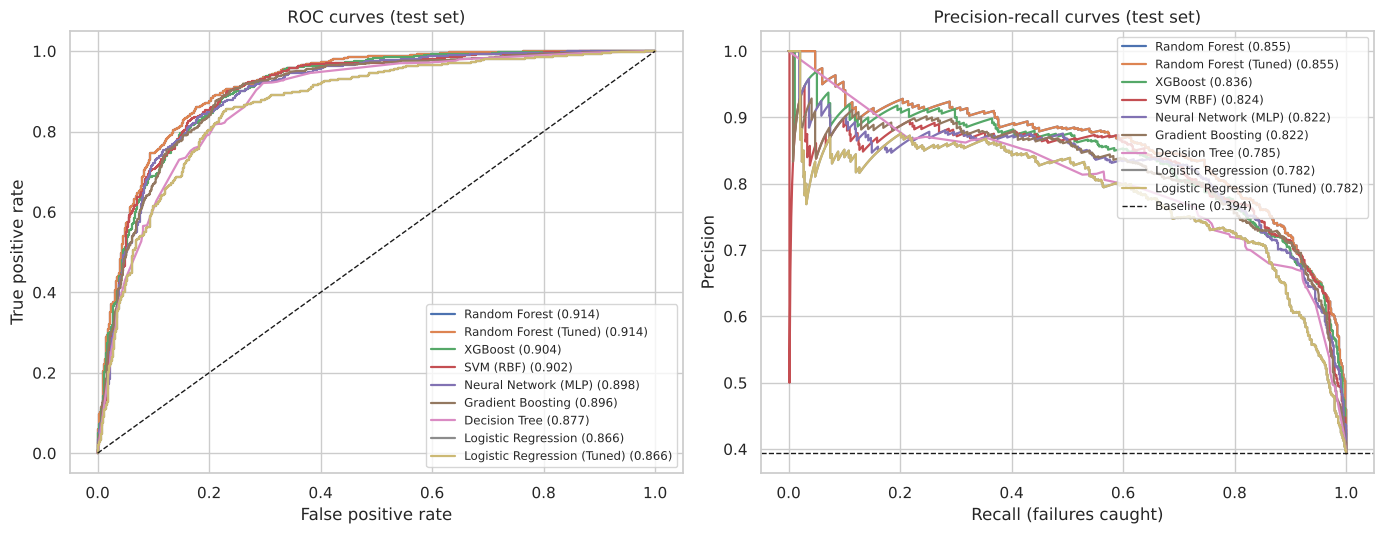

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name in comparison['Model']:
    s = get_scores(models[name], X_test)
    fpr, tpr, _ = roc_curve(y_test, s)
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[0].plot(fpr, tpr, lw=1.6, label=f"{name} ({roc_auc_score(y_test, s):.3f})")
    axes[1].plot(rec, prec, lw=1.6, label=f"{name} ({average_precision_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set(title='ROC curves (test set)', xlabel='False positive rate', ylabel='True positive rate')
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1, label=f'Baseline ({y_test.mean():.3f})')
axes[1].set(title='Precision-recall curves (test set)', xlabel='Recall (failures caught)', ylabel='Precision')
for ax in axes:
    ax.legend(fontsize=8.5, loc='lower right' if ax is axes[0] else 'upper right')
plt.tight_layout()
plt.show()

Best model by test ROC-AUC: Random Forest


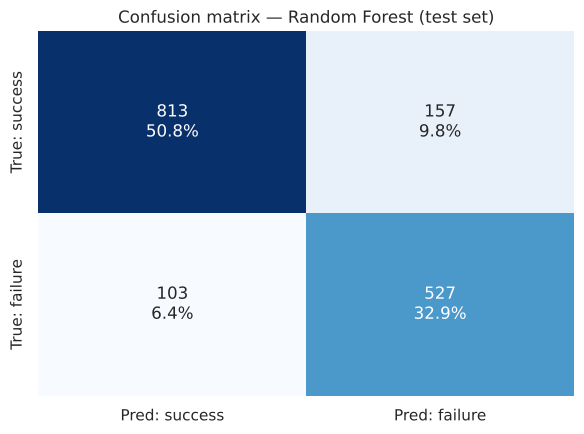

              precision    recall  f1-score   support

     success       0.89      0.84      0.86       970
     failure       0.77      0.84      0.80       630

    accuracy                           0.84      1600
   macro avg       0.83      0.84      0.83      1600
weighted avg       0.84      0.84      0.84      1600



In [22]:
best_name = comparison.loc[0, 'Model']
best = models[best_name]
print('Best model by test ROC-AUC:', best_name)
plot_confusion(best, X_test, y_test, f'Confusion matrix — {best_name} (test set)')

### Does the model learn more than which method was used?
Search method alone explains a lot, since LSA fails far more often than BM25. A fair check is to compare against a model that only knows the method, and to measure how well the best model ranks failures **within** each method.

In [23]:
method_only = make_pipe(LogisticRegression(max_iter=1000))
method_only.set_params(prep=ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), ['method'])]))
method_only.fit(X_train, y_train)
print(f"Method-only baseline test ROC-AUC: {roc_auc_score(y_test, get_scores(method_only, X_test)):.3f}")
print(f"{best_name} test ROC-AUC:           {roc_auc_score(y_test, get_scores(best, X_test)):.3f}")

within = []
for m in sorted(X_test['method'].unique()):
    mask = X_test['method'] == m
    within.append({'Method': m, 'Test rows': int(mask.sum()), 'Failure rate': y_test[mask].mean(),
                   'ROC-AUC within method': roc_auc_score(y_test[mask], get_scores(best, X_test[mask]))})
display(pd.DataFrame(within).round(3))

Method-only baseline test ROC-AUC: 0.748
Random Forest test ROC-AUC:           0.914


,Method,Test rows,Failure rate,ROC-AUC within method
0,BM25,400,0.170,0.938
1,Hybrid,400,0.480,0.862
2,LSA,400,0.712,0.804
3,TF-IDF,400,0.212,0.926


## 13. Feature Importance
Permutation importance shuffles one predictor at a time and measures how much test ROC-AUC drops. It works for any model and is computed on the original columns, so each categorical variable is scored as a whole rather than one dummy at a time.

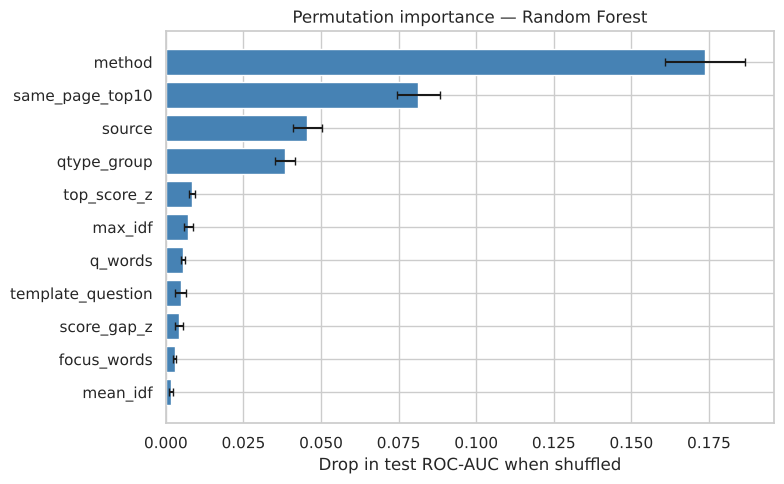

In [24]:
perm = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
err = pd.Series(perm.importances_std, index=FEATURES)[imp.index]

plt.figure(figsize=(8, 5))
plt.barh(imp.index, imp.values, xerr=err.values, color='steelblue', capsize=3)
plt.title(f'Permutation importance — {best_name}')
plt.xlabel('Drop in test ROC-AUC when shuffled')
plt.tight_layout()
plt.show()

In [25]:
# Logistic regression odds ratios for the numeric predictors (per 1 standard deviation)
lr = models['Logistic Regression (Tuned)']
names = lr.named_steps['prep'].get_feature_names_out()
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=names)
odds = np.exp(coef[[f'num__{c}' for c in NUMERIC]]).rename(lambda s: s.replace('num__', ''))
odds.sort_values().round(2).to_frame('Odds ratio of failure (per 1 SD)')

,Odds ratio of failure (per 1 SD)
same_page_top10,0.42
template_question,0.72
score_gap_z,0.88
mean_idf,0.90
top_score_z,0.95
focus_words,0.97
q_words,1.09
max_idf,1.14


## 14. Interpretation of Findings
**1. The search methods fail at very different rates.** BM25 missed the correct answer for 16% of questions, TF-IDF for 20%, the hybrid for 50%, and LSA for 72%. Cochran's Q test shows the methods differ (p < 0.001), and every pairwise McNemar test is significant after the Bonferroni correction. LSA, a classical semantic method, is poor at finding one exact passage among 13,000. Because the hybrid combines BM25 with LSA, the weak LSA ranking pulled it well below BM25 alone. A hybrid only helps when both of its parts are reasonably good.

**2. Question type is related to failure.** The chi-square test is significant (p < 0.001) with a moderate effect size (Cramér's V = 0.28). Research, inheritance, and outlook questions fail most often across all methods, while causes and symptoms questions rarely fail with BM25. One likely reason is that many NIH pages have a similar research or outlook section, so these questions are easy to match to the wrong page.

**3. Failure is predictable.** The random forest was the best model, with a test ROC-AUC of 0.914 and a PR-AUC of 0.855, compared with a baseline PR-AUC of 0.394. It caught 84% of failed searches with 77% precision. The ensemble models (random forest, XGBoost) and the SVM beat logistic regression (0.866) and the single decision tree (0.877), which suggests the predictors interact in ways a linear model misses. The random forest scored higher on training data (0.965) than test data, so it overfits somewhat, but its cross-validated ROC-AUC was stable (0.906 ± 0.005).

**4. The model learns more than which method was used.** A model that only knows the search method reaches a test ROC-AUC of 0.748, well below 0.914. Within BM25 alone, the random forest ranks failures with a ROC-AUC of 0.938. This is the result that matters for a real system, since it means failures can be flagged even for the best search method.

**5. The strongest question-level signal is whether the top results agree.** When most of the top 10 results come from the same NIH page, the search found the right topic and usually succeeds. Each one standard deviation increase in `same_page_top10` cuts the odds of failure by more than half (odds ratio 0.42). Template questions ("What is (are) ...") fail less often (odds ratio 0.72). The score gap was statistically significant in the Mann-Whitney test, but the effect is very small (r = 0.06). With 8,000 rows, even tiny differences reach significance, so effect sizes matter more than p-values here.

**6. Tuning did not change the models.** The grid search chose the default settings for both logistic regression and the random forest, so the tuned and untuned versions are identical.

**Limitations.** MedQuAD questions follow templates and are cleaner than real patient questions. The target depends on which search methods I ran, so the results describe these four methods, not search in general. LSA is an older semantic method. Modern neural embeddings would likely perform much better, and I plan to add them for the final submission if compute allows. The test set is one fold of 400 questions.

**Next steps for the final submission.** Choose a probability threshold for flagging likely failures based on the cost of a missed failure, add SHAP explanations for the best model, and test neural embedding search.

## 15. Pipeline Enhancements
| # | Enhancement | What was modified | Why | How it improves the workflow |
|---|---|---|---|---|
| 1 | **Central configuration cell** | All settings (sample size, top K, seed, folds, file paths, cache flag) moved to one cell at the top | Settings were scattered through the code in the lab notebook | The whole analysis can be changed or rerun by editing one cell, and every random step uses the same seed |
| 2 | **Modular functions** | Loading, validation, the four search methods, evaluation, and plotting are written once as documented functions | The same steps run for many methods and models | Less repeated code, fewer copy-paste errors, and each step is easier to test and reuse in the capstone |
| 3 | **Data validation with clear errors** | `validate_raw()` checks required columns and unique IDs. `validate_model_table()` checks for a binary target, at least 300 rows, at least 10 predictors, and no missing values | Problems in the data should stop the pipeline early instead of producing silently wrong models | Errors explain exactly what is wrong, and the course requirements are checked automatically |
| 4 | **Feature engineering** | Scores standardized within each method, a template-question flag, and rare question types grouped into "other" | Raw scores are on different scales for each method, and tiny categories are unstable | Predictors are comparable across methods and categorical variables are reliable |
| 5 | **Conditional data loading and caching** | Data loads from a local file, then the GitHub repo, then the original MedQuAD XML. Search results can be reused with `USE_CACHED_RETRIEVAL` | The notebook should run anywhere, and the search step is the slowest part | Runs in Colab with no manual upload, and reruns are faster when only the models change |
| 6 | **Leakage-safe grouped splitting** | `StratifiedGroupKFold` for the test split, cross-validation, and grid search, plus an `assert` that no question is in both train and test | Each question appears four times. A random split would let the model see test questions during training | Performance estimates are honest instead of inflated |
| 7 | **Additional metrics and comparison visuals** | Added PR-AUC, balanced accuracy, Brier score, cross-validated ROC-AUC with spread, overlaid ROC and precision-recall curves, and a highlighted comparison table | Accuracy alone is misleading when failure is the minority class | Models are compared on the failure class that matters, and calibration and stability are visible |